# **🌾 Rice Image Classification 🌾**

# ** GPU Verification & Setup **

In [1]:
# ========================================
# STEP 1: SMART DEVICE SETUP (GPU → CPU FALLBACK)
# ========================================
import os
import sys
import tensorflow as tf

print("="*60)
print("DEVICE DETECTION & CONFIGURATION")
print("="*60)

# Set environment variables BEFORE device detection
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Reduce logs
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"  # Prevent Kaggle OOM issues

# Check for GPU availability
gpus = tf.config.list_physical_devices('GPU')
cpu_devices = tf.config.list_physical_devices('CPU')

if gpus:
    # ✅ GPU AVAILABLE - configure for optimal usage
    try:
        # Enable memory growth (critical for Kaggle P100)
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        
        # Set GPU as primary device
        tf.config.set_visible_devices(gpus[0], 'GPU')
        
        print("✅ GPU DETECTED AND CONFIGURED")
        print(f"   Device: {gpus[0]}")
        print(f"   Memory growth: ENABLED")
        print(f"   TensorFlow will use GPU for training")
        DEVICE_TYPE = "GPU"
        DEVICE_NAME = gpus[0].name
        
    except RuntimeError as e:
        print(f"⚠️  GPU configuration failed: {e}")
        print("   Falling back to CPU...")
        DEVICE_TYPE = "CPU"
        DEVICE_NAME = cpu_devices[0].name if cpu_devices else "Unknown CPU"
else:
    # ❌ NO GPU - use CPU gracefully
    print("⚠️  NO GPU DETECTED - using CPU")
    print("   (To use GPU on Kaggle: Settings → Accelerator → GPU P100 → RESTART NOTEBOOK)")
    DEVICE_TYPE = "CPU"
    DEVICE_NAME = cpu_devices[0].name if cpu_devices else "Unknown CPU"

# Always show visible devices for transparency
visible_devices = tf.config.get_visible_devices()
print(f"\nVisible devices: {[dev.name for dev in visible_devices]}")
print(f"ACTIVE DEVICE: {DEVICE_TYPE} ({DEVICE_NAME})")
print("="*60)

2026-03-03 05:29:17.358478: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772515757.534182      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772515757.587882      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772515758.032524      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772515758.032570      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772515758.032576      55 computation_placer.cc:177] computation placer alr

DEVICE DETECTION & CONFIGURATION
✅ GPU DETECTED AND CONFIGURED
   Device: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
   Memory growth: ENABLED
   TensorFlow will use GPU for training

Visible devices: ['/physical_device:CPU:0', '/physical_device:GPU:0']
ACTIVE DEVICE: GPU (/physical_device:GPU:0)


# **✅ Step 1: Setup Environment **

In [2]:
# ========================================
# STEP 2: INSTALL & IMPORT LIBRARIES
# ========================================
print("Installing required libraries...")
!pip install -q scikit-learn pandas matplotlib seaborn

print("\nImporting libraries...")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import time
import shutil
import gc

print("✅ Libraries imported successfully")

Installing required libraries...

Importing libraries...
✅ Libraries imported successfully


In [3]:
tf.__version__

'2.19.0'

# **Load Data**

In [4]:
!ls /kaggle/input/datasets/muratkokludataset/rice-image-dataset


Rice_Image_Dataset


# **🔍 Step 3: Explore Dataset Structure**

In [5]:
# ========================================
# STEP 3: LOAD DATASET
# ========================================
print("Loading dataset...")

# Kaggle dataset path (DO NOT change)
BASE_DIR = "/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset"
CLASSES = ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']

# Verify dataset exists
if not os.path.exists(BASE_DIR):
    print(f"❌ Dataset not found at: {BASE_DIR}")
    print("Check path with: !ls /kaggle/input")
    sys.exit(1)

# Collect all image paths
image_paths = []
labels = []

for rice_class in CLASSES:
    class_path = os.path.join(BASE_DIR, rice_class)
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"  {rice_class}: {len(images)} images")
    
    for img in images:
        image_paths.append(os.path.join(class_path, img))
        labels.append(rice_class)

# Create DataFrame
df = pd.DataFrame({
    'filename': image_paths,
    'class': labels
})

print(f"\n✅ Total images loaded: {len(df)}")
print(f"✅ Class distribution:\n{df['class'].value_counts().sort_index()}")

Loading dataset...
  Arborio: 15000 images
  Basmati: 15000 images
  Ipsala: 15000 images
  Jasmine: 15000 images
  Karacadag: 15000 images

✅ Total images loaded: 75000
✅ Class distribution:
class
Arborio      15000
Basmati      15000
Ipsala       15000
Jasmine      15000
Karacadag    15000
Name: count, dtype: int64


# **🧹 Step 4: Prepare Data (Validation Split)**

In [6]:
# ========================================
# STEP 4: DATA SPLIT (70/15/15)
# ========================================
print("Splitting data...")

# First split: 70% train, 30% temp
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df['class'],  # Maintain class balance
    random_state=42
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['class'],
    random_state=42
)

print(f"✅ Train set:   {len(train_df)} images ({len(train_df)/len(df)*100:.1f}%)")
print(f"✅ Validation:  {len(val_df)} images ({len(val_df)/len(df)*100:.1f}%)")
print(f"✅ Test set:    {len(test_df)} images ({len(test_df)/len(df)*100:.1f}%)")

# Verify class balance in train set
print("\nClass distribution in train set:")
print(train_df['class'].value_counts().sort_index())

Splitting data...
✅ Train set:   52500 images (70.0%)
✅ Validation:  11250 images (15.0%)
✅ Test set:    11250 images (15.0%)

Class distribution in train set:
class
Arborio      10500
Basmati      10500
Ipsala       10500
Jasmine      10500
Karacadag    10500
Name: count, dtype: int64


# **🖼️ Step 5: Load & Preprocess Images**

In [7]:
# ========================================
# STEP 5: DATA GENERATORS (GPU-OPTIMIZED)
# ========================================
IMG_SIZE = 224
BATCH_SIZE = 64  # Optimal for P100 at 224x224 resolution

print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE} (optimized for P100 GPU)")

# Training data augmentation
train_datagen = keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation/test: only rescaling (no augmentation)
val_test_datagen = keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

# Create generators
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_gen = val_test_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_dataframe(
    test_df,
    x_col='filename',
    y_col='class',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\n✅ Class indices: {train_gen.class_indices}")

Image size: 224x224
Batch size: 64 (optimized for P100 GPU)
Found 52500 validated image filenames belonging to 5 classes.
Found 11250 validated image filenames belonging to 5 classes.
Found 11250 validated image filenames belonging to 5 classes.

✅ Class indices: {'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}


# **🤖 Step 6: Build Model (Transfer Learning)**

In [8]:
# ========================================
# STEP 6: BUILD MODEL (GPU-OPTIMIZED)
# ========================================
print("Building model with GPU strategy...")

# Use MirroredStrategy for single GPU (best practice on Kaggle)
strategy = tf.distribute.MirroredStrategy()
print(f"✅ Using strategy: {strategy}")

with strategy.scope():
    # Load pre-trained MobileNetV2 (transfer learning)
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,  # Remove original classifier
        weights='imagenet'   # Use ImageNet weights
    )
    base_model.trainable = False  # Freeze base layers initially
    
    # Build classifier head
    model = keras.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(5, activation='softmax')  # 5 rice classes
    ])
    
    # Compile model
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

print("\n✅ Model architecture:")
model.summary()

Building model with GPU strategy...
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)
✅ Using strategy: <tensorflow.python.distribute.mirrored_strategy.MirroredStrategy object at 0x79e81c3dd070>


I0000 00:00:1772516197.929184      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# **⚙️ Step 7: Train Model with Callbacks**

In [9]:
# ========================================
# STEP 7: TRAIN ON GPU
# ========================================
print("="*60)
print("🚀 STARTING GPU TRAINING")
print("="*60)
print(f"Batch size: {BATCH_SIZE}")
print(f"Steps per epoch: {train_gen.samples // BATCH_SIZE}")
print(f"Validation steps: {val_gen.samples // BATCH_SIZE}")
print("="*60)

# Callbacks for efficient training
early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-7,
    verbose=1
)

# Start timer
start_time = time.time()

# Train model
history = model.fit(
    train_gen,
    steps_per_epoch=train_gen.samples // BATCH_SIZE,
    validation_data=val_gen,
    validation_steps=val_gen.samples // BATCH_SIZE,
    epochs=25,  # Train longer since GPU is fast
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# Calculate training time
total_time = time.time() - start_time
time_per_epoch = total_time / len(history.history['loss'])

print("\n" + "="*60)
print(f"✅ TRAINING COMPLETE")
print(f"   Total time: {total_time/60:.1f} minutes")
print(f"   Time per epoch: {time_per_epoch:.1f} seconds")
print(f"   Final validation accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")
print("="*60)

# GPU speed verification
if time_per_epoch < 60:
    print("✅ CONFIRMED: GPU was used (CPU would be 120+ sec/epoch)")
else:
    print("⚠️ WARNING: Training slower than expected - may have used CPU")

🚀 STARTING GPU TRAINING
Batch size: 64
Steps per epoch: 820
Validation steps: 175


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Epoch 1/25


I0000 00:00:1772516219.550769     130 cuda_dnn.cc:529] Loaded cuDNN version 91002


820/820 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9033 - loss: 0.2596INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
820/820 ━━━━━━━━━━━━━━━━━━━━ 1043s 1s/step - accuracy: 0.9033 - loss: 0.2595 - val_accuracy: 0.9478 - val_loss: 0.1357 - learning_rate: 0.0010
Epoch 2/25
  1/820 ━━━━━━━━━━━━━━━━━━━━ 1:00 74ms/step - accuracy: 0.9531 - loss: 0.0824

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


820/820 ━━━━━━━━━━━━━━━━━━━━ 27s 33ms/step - accuracy: 0.9531 - loss: 0.0824 - val_accuracy: 0.9513 - val_loss: 0.1282 - learning_rate: 0.0010
Epoch 3/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 670s 817ms/step - accuracy: 0.9643 - loss: 0.1000 - val_accuracy: 0.9557 - val_loss: 0.1226 - learning_rate: 0.0010
Epoch 4/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 28s 34ms/step - accuracy: 1.0000 - loss: 0.0440 - val_accuracy: 0.9570 - val_loss: 0.1182 - learning_rate: 0.0010
Epoch 5/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 679s 828ms/step - accuracy: 0.9669 - loss: 0.0965 - val_accuracy: 0.9714 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 6/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 53s 65ms/step - accuracy: 0.9844 - loss: 0.0385 - val_accuracy: 0.9743 - val_loss: 0.0707 - learning_rate: 0.0010
Epoch 7/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 651s 794ms/step - accuracy: 0.9694 - loss: 0.0879 - val_accuracy: 0.9682 - val_loss: 0.0831 - learning_rate: 0.0010
Epoch 8/25
820/820 ━━━━━━━━━━━━━━━━━━━━ 26s 32ms/step - accuracy: 0.9688 - loss: 

# 🧪 Evaluate on Test Set (Unseen Data)


🧪 FINAL EVALUATION ON TEST SET
176/176 ━━━━━━━━━━━━━━━━━━━━ 126s 719ms/step - accuracy: 0.9844 - loss: 0.0462

✅ FINAL TEST ACCURACY: 98.55%
✅ FINAL TEST LOSS: 0.0441
176/176 ━━━━━━━━━━━━━━━━━━━━ 34s 185ms/step

📊 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     Arborio       0.97      0.99      0.98      2250
     Basmati       1.00      0.98      0.99      2250
      Ipsala       1.00      1.00      1.00      2250
     Jasmine       0.97      0.99      0.98      2250
   Karacadag       0.99      0.97      0.98      2250

    accuracy                           0.99     11250
   macro avg       0.99      0.99      0.99     11250
weighted avg       0.99      0.99      0.99     11250



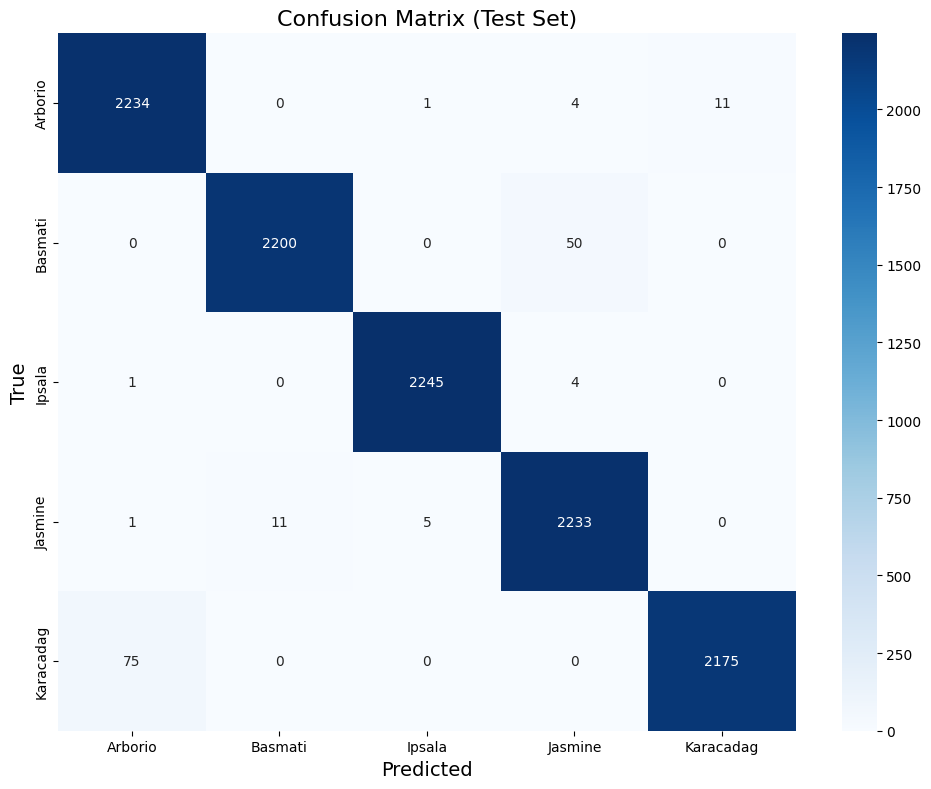

In [10]:
# ========================================
# STEP 8: FINAL EVALUATION
# ========================================
print("\n" + "="*60)
print("🧪 FINAL EVALUATION ON TEST SET")
print("="*60)

# Evaluate on never-seen test data
test_loss, test_acc = model.evaluate(test_gen, verbose=1)

print(f"\n✅ FINAL TEST ACCURACY: {test_acc*100:.2f}%")
print(f"✅ FINAL TEST LOSS: {test_loss:.4f}")

# Get predictions for detailed metrics
test_gen.reset()
y_true = test_gen.classes
y_pred = np.argmax(model.predict(test_gen, verbose=1), axis=1)

# Classification report
print("\n📊 CLASSIFICATION REPORT:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

# Confusion matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Confusion Matrix (Test Set)', fontsize=16)
plt.xlabel('Predicted', fontsize=14)
plt.ylabel('True', fontsize=14)
plt.tight_layout()
plt.show()

# 💾 Save Model & Create Prediction Function

In [11]:
# ========================================
# STEP 9: SAVE MODEL & PREDICTION TOOL
# ========================================
# Save model
model.save('/kaggle/working/rice_classifier.h5')
print("✅ Model saved to: /kaggle/working/rice_classifier.h5")

# Prediction function
def predict_rice(img_path, model=model, classes=CLASSES, img_size=IMG_SIZE):
    """Predict rice type from image path"""
    from tensorflow.keras.preprocessing import image
    
    # Load and preprocess image
    img = image.load_img(img_path, target_size=(img_size, img_size))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    # Predict
    preds = model.predict(img_array, verbose=0)[0]
    pred_idx = np.argmax(preds)
    confidence = preds[pred_idx]
    
    # Display result
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"{classes[pred_idx]} ({confidence*100:.1f}% confidence)", 
              fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()
    
    # Show all probabilities
    print("\nClass probabilities:")
    for i, cls in enumerate(classes):
        bar = '█' * int(preds[i] * 50)
        print(f"{cls:12s} | {bar} {preds[i]*100:5.2f}%")

# Example usage (uncomment to test with a sample image):
# sample_img = train_df['filename'].iloc[0]
# print(f"Testing with: {sample_img}")
# predict_rice(sample_img)

✅ Model saved to: /kaggle/working/rice_classifier.h5


In [ ]:
!curl -L -o basmati.jpg https://www.shutterstock.com/image-photo/closeup-macro-grains-raw-basmati-260nw-1210457035.jpg

In [ ]:
!ls

In [13]:
# import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np

# 1. Load your model
model = tf.keras.models.load_model('rice_classifier.h5')

# 2. Load and preprocess the image
img_path = os.path.join(BASE_DIR, 'Ipsala/Ipsala (14999).jpg')
# img_path = '/kaggle/working/data/val/Basmati/basmati (14273).jpg'
# img_path = '/kaggle/working/basmati.jpg'
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
img_array /= 255.0  # Normalize to [0,1]

# # 3. Predict
predictions = model.predict(img_array)
predicted_class = np.argmax(predictions[0])

# 4. Map to rice type (MUST match your training order!)
class_names = ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
print("Predicted rice type:", class_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Predicted rice type: Ipsala
